# **Write and Save Files**

## **Writing Files**

 We can open a file object using the method <code>write()</code> to save the text file to a list. To write to a file, the mode argument must be set to **w**. Let’s write a file **Example2.txt** with the line: **“This is line A”**


In [3]:
# Write line to file

example2 = 'Example2.txt'
with open(example2, 'w') as writefile:
    writefile.write("This is line A")

 We can read the file to see if it worked:


In [4]:
# Read file

with open(example2, 'r') as testwritefile:
    print(testwritefile.read())

This is line A


We can write multiple lines:


In [5]:
# Write lines to file

with open(example2, 'w') as writefile:
    writefile.write("This is line A\n")
    writefile.write("This is line B\n")

The method <code>.write()</code> works similar to the method <code>.readline()</code>, except instead of reading a new line it writes a new line. The process is illustrated in the figure. The different colour coding of the grid represents a new 
line added to the file after each method call.

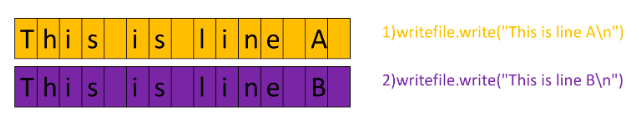

You can check the file to see if your results are correct 


In [7]:
# Check whether write to file

with open(example2, 'r') as testwritefile:
    print(testwritefile.read())

This is line A
This is line B



 We write a list to a **.txt** file  as follows:


In [8]:
Lines = ["This is line A\n", "This is line B\n", "This is line C\n"]
Lines

['This is line A\n', 'This is line B\n', 'This is line C\n']

In [9]:
# Write the strings in the list to text file

with open('Example2', 'w') as writefile:
    for line in Lines:
        print(line)
        writefile.write(line)

This is line A

This is line B

This is line C



 We can verify the file is written by reading it and printing out the values:  


In [10]:
# Verify if writing to file is successfully executed

with open('Example2.txt', 'r') as testwritefile:
    print(testwritefile.read())

This is line A
This is line B



However, note that setting the mode to __w__ overwrites all the existing data in the file.


In [14]:
with open('Example2.txt', 'w') as writefile:
    writefile.write("Overwrite\n")
    
with open('Example2.txt', 'r') as testwritefile:
    print(testwritefile.read())

Overwrite



### **Appending Files**

 We can write to files without losing any of the existing data as follows by setting the mode argument to append: **a**.  you can append a new line as follows:


In [15]:
# Write a new line to text file

with open('Example2.txt', 'a') as testwritefile:
    testwritefile.write("This is line C\n")
    testwritefile.write("This is line D\n")
    testwritefile.write("This is line E\n")

 You can verify the file has changed by running the following cell:


In [16]:
# Verify if the new line is in the text file

with open('Example2.txt', 'r') as testwritefile:
    print(testwritefile.read())

Overwrite
This is line C
This is line D
This is line E



### **Additional modes**

It's fairly ineffecient to open the file in **a** or **w** and then reopening it in **r** to read any lines. Luckily we can access the file in the following modes:
- **r+** : Reading and writing. Cannot truncate the file.
- **w+** : Writing and reading. Truncates the file.
- **a+** : Appending and Reading. Creates a new file, if none exists.
You dont have to dwell on the specifics of each mode for this lab. 

Let's try out the __a+__ mode:


In [18]:
with open('Example2.txt', 'a+') as testwritefile:
    testwritefile.write("This is line F\n")
    print(testwritefile.read())

There were no errors but <code>read()</code> also did not output anything. This is because of our location in the file.


Most of the file methods we've looked at work in a certain location in the file. <code>.write() </code> writes at a certain location in the file. <code>.read()</code> reads at a certain location in the file and so on. You can think of this as moving your pointer around in the notepad to make changes at specific location.


Opening the file in **w** is asking to opening the .txt file, moving your cursor to the beginning of the text file, writing new text and deleting everything that follows.
Whereas opening the file in **a** is similiar to opening the .txt file, moving your cursor to the very end and then adding the new pieces of text. <br>
It is often very useful to know where the 'cursor' is in a file and be able to control it. The following methods allow us to do precisely this -
- <code>.tell()</code> - returns the current position in bytes
- <code>.seek(offset,from)</code> - changes the position by 'offset' bytes with respect to 'from'. From can take the value of 0,1,2 corresponding to beginning, relative to current position and end

Now lets revisit **a+**


In [21]:
with open('Example2.txt', 'a+') as testwritefile:
    print("Initial Location: {}".format(testwritefile.tell()))

    data = testwritefile.read()
    if (not data): # empty string return false in python
        print("Read nothing")
    else:
        print(data)

    testwritefile.seek(0,0) # move 0 bytes from beginning.

    print("\nNew Location : {}".format(testwritefile.tell()))
    data = testwritefile.read()
    if (not data):
        print('Read nothing')
    else:
        print(data)
    print("Location ater read: {}".format(testwritefile.tell()))

Initial Location: 75
Read nothing

New Location : 0
Overwrite
This is line C
This is line D
This is line E
This is line F

Location ater read: 75


Finally, a note on the difference between **w+** and **r+**. Both of these modes allow access to read and write methods, however, opening a file in **w+** overwrites it and deletes all pre-existing data. <br>

In the following code block, Run the code as it is first and then run it without the <code>.truncate()</code>.

In [23]:
with open('Example2.txt', 'r+') as testwritefile:
    testwritefile.seek(0,0) # write at beginning of file
    testwritefile.write("Line 1" + "\n")
    testwritefile.write("Line 2" + "\n")
    testwritefile.write("Line 3" + "\n")
    testwritefile.write("Line 4" + "\n")
    testwritefile.write("finished\n")
    testwritefile.seek(0,0)
    print(testwritefile.read())

Line 1
Line 2
Line 3
Line 4
finished

This is line E
This is line F



To work with a file on existing data, use **r+** and **a+**. While using **r+**, it can be useful to add a <code>.truncate()</code> method at the end of your data. This will reduce the file to your data and delete everything that follows. <br>


In [24]:
with open('Example2.txt', 'r+') as testwritefile:
    testwritefile.seek(0,0) # write at beginning of file
    testwritefile.write("Line 1" + "\n")
    testwritefile.write("Line 2" + "\n")
    testwritefile.write("Line 3" + "\n")
    testwritefile.write("Line 4" + "\n")
    testwritefile.write("finished\n")
    testwritefile.truncate()
    testwritefile.seek(0,0)
    print(testwritefile.read())

Line 1
Line 2
Line 3
Line 4
finished



### **Copy a File**

Let's copy the file **Example2.txt** to the file **Example3.txt**:


In [26]:
# Copy file to another

with open('Example2.txt', 'r') as readfile:
    with open('Example3.txt', 'w') as writefile:
        for line in readfile:
            writefile.write(line)

We can read the file to see if everything works:


In [27]:
# Verify if the copy is successfully executed

with open('Example3.txt', 'r') as readfile:
    print(readfile.read())

Line 1
Line 2
Line 3
Line 4
finished



 After reading files, we can also write data into files and save them in different file formats like **.txt, .csv, .xls (for excel files) etc**. You will come across these in further examples


### **Exercise**

Your local university's Raptors fan club maintains a register of its active members on a .txt document. Every month they update the file by removing the members who are not active. You have been tasked with automating this with your Python skills. <br>

Given the file `currentMem`, Remove each member with a 'no' in their Active column. Keep track of each of the removed members and append them to the `exMem` file. Make sure that the format of the original files in preserved.   (*Hint: Do this by reading/writing whole lines and ensuring the header remains* )
<br>

Run the code block below prior to starting the exercise. The skeleton code has been provided for you. Edit only the `cleanFiles` function.

In [28]:
# Run this prior to starting the exercise
from random import randint as rnd

memReg = 'members.txt'
exReg = 'inactive.txt'
fee = ('yes', 'no')

def genFiles(current, old):
    with open(current, 'w+') as writefile:
        writefile.write('Membership No  Date    Joined  Active  \n')
        data = "{:^13}  {:<11}  {:<6}\n"

        for rowno in range(20):
            date = str(rnd(2015,2020)) + '-' + str(rnd(1,12)) + '-' + str(rnd(1,25))
            writefile.write(data.format(rnd(10000,99999),date,fee[rnd(0,1)]))

    with open(old, 'w+') as writefile:
        writefile.write('Membership No  Date    Joined  Active  \n')
        data = "{:^13}  {:<11}  {:<6}\n"
        for rowno in range(3):
            date = str(rnd(2015, 2020)) + '-' + str(rnd(1,25))
            writefile.write(data.format(rnd(10000,99999), date, fee[1]))

genFiles(memReg,exReg)

Now that you've run the prerequisite code cell above, which prepared the files for this exercise, you are ready to move on to the implementation.

#### **Exercise:** Implement the cleanFiles function in the code cell below.

In [29]:
def cleanFiles(currentMem,exMem):
    with open(currentMem, 'r+') as writeFile:
        with open(exMem, 'a+') as appendFile:
            # get the data
            writeFile.seek(0)
            members = writeFile.readlines()
            # remove header
            header = members[0]
            members.pop(0)

            inactive = [member for member in members if ('no' in member)]

            # go to the beginning of the write file
            writeFile.seek(0)
            writeFile.write(header)
            for member in members:
                if(member in inactive):
                    appendFile.write(member)
                else:
                    writeFile.write(member)
            writeFile.truncate()

memReg = 'members.txt'
exReg = 'ianctive.txt'
cleanFiles(memReg, exReg)

# code to see the files

headers = "Membership   No  Date    Joined  Active  \n"

with open(memReg, 'r') as readFile:
    print("Active Members: \n\n")
    print(readFile.read())

with open(exReg, 'r') as readFile:
    print("Inactive Members: \n\n")
    print(readFile.read())

Active Members: 


Membership No  Date    Joined  Active  
    39905      2017-10-22   yes   
    18666      2019-4-5     yes   
    96412      2017-6-19    yes   
    17896      2017-11-24   yes   
    40453      2017-4-2     yes   
    41246      2017-3-16    yes   
    54107      2017-10-2    yes   
    94313      2019-7-20    yes   
    33551      2015-11-5    yes   
    44842      2016-1-4     yes   

Inactive Members: 


    52467      2020-11-15   no    
    66969      2017-2-6     no    
    59703      2017-3-8     no    
    24628      2016-1-8     no    
    29941      2018-1-6     no    
    11735      2018-2-14    no    
    17654      2015-9-3     no    
    42045      2015-7-4     no    
    10681      2020-10-6    no    
    15606      2020-2-8     no    

